# 01 — Sanity Check

Verify our 5 agents reproduce expected qualitative behavior on the
deterministic cliff (van Seijen Fig 2 pattern). This is a smoke test,
not a paper figure.


In [2]:
import sys, os, time
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt

from envs import (CliffWalking, StochasticCliff,
                  CorridorCliff, StochasticCorridorCliff)
from agents import (run_sarsa, run_q_learning, run_expected_sarsa,
                    run_double_expected_sarsa, run_rr_expected_sarsa)
from utils import (multi_seed_run, smooth,
                   bootstrap_mean_ci, bootstrap_diff_ci, pairwise_table,
                   rollout_metrics, regret_to_convergence)

# ---- Run configuration ----
# Set N_RUNS=50 for pilot, bump to 500 for final overnight run
N_RUNS = 50
N_EPISODES = 100
EPS_DEFAULT = 0.1
ALPHA_DEFAULT = 0.3
SLIP = 0.2
RR_DELTA = 1.0   # RR-ES regret threshold used in most experiments

def sem(arr, axis=0):
    return arr.std(axis=axis, ddof=1) / np.sqrt(arr.shape[axis])

# ---- Environment factories ----
def env_det(seed=None):   return CliffWalking()
def env_stoch(seed=None): return StochasticCliff(slip_prob=SLIP, rng_seed=seed)
def env_corr(seed=None):  return CorridorCliff()
def env_scor(seed=None):  return StochasticCorridorCliff(slip_prob=SLIP, rng_seed=seed)

ENVS = {
    'Det Cliff':        env_det,
    'Stoch Cliff':      env_stoch,
    'Corr Cliff':       env_corr,
    'Stoch Corr Cliff': env_scor,
}

# ---- Method registry ----
METHODS = {
    'SARSA':          (run_sarsa,                {}),
    'Q-learning':     (run_q_learning,           {}),
    'Expected SARSA': (run_expected_sarsa,       {}),
    'Double ES':      (run_double_expected_sarsa, {}),
    f'RR-ES (δ={RR_DELTA})': (run_rr_expected_sarsa, {'delta': RR_DELTA}),
}

METHOD_COLORS = {
    'SARSA':              '#1f77b4',
    'Q-learning':         '#ff7f0e',
    'Expected SARSA':     '#2ca02c',
    'Double ES':          '#9467bd',
    f'RR-ES (δ={RR_DELTA})': '#d62728',
}
METHOD_MARKERS = {
    'SARSA':              'o',
    'Q-learning':         's',
    'Expected SARSA':     '^',
    'Double ES':          'v',
    f'RR-ES (δ={RR_DELTA})': 'D',
}


In [3]:
ALPHAS = np.array([0.1, 0.3, 0.5, 0.7, 0.9, 1.0])
results = {name: np.zeros(len(ALPHAS)) for name in METHODS}

t0 = time.time()
for i, a in enumerate(ALPHAS):
    for name, (fn, kw) in METHODS.items():
        ret = multi_seed_run(fn, env_det, N_RUNS, N_EPISODES,
                             alpha=a, eps=EPS_DEFAULT,
                             progress=True, desc=f'{name} α={a}', **kw)
        results[name][i] = ret.mean()
print(f'done in {time.time()-t0:.0f}s')


SARSA α=0.1:   0%|          | 0/50 [00:00<?, ?it/s]

Q-learning α=0.1:   0%|          | 0/50 [00:00<?, ?it/s]

Expected SARSA α=0.1:   0%|          | 0/50 [00:00<?, ?it/s]

Double ES α=0.1:   0%|          | 0/50 [00:00<?, ?it/s]

RR-ES (δ=1.0) α=0.1:   0%|          | 0/50 [00:00<?, ?it/s]

SARSA α=0.3:   0%|          | 0/50 [00:00<?, ?it/s]

... (21 outputs left out)

Expected SARSA α=1.0:   0%|          | 0/50 [00:00<?, ?it/s]

Double ES α=1.0:   0%|          | 0/50 [00:00<?, ?it/s]

RR-ES (δ=1.0) α=1.0:   0%|          | 0/50 [00:00<?, ?it/s]

done in 114s


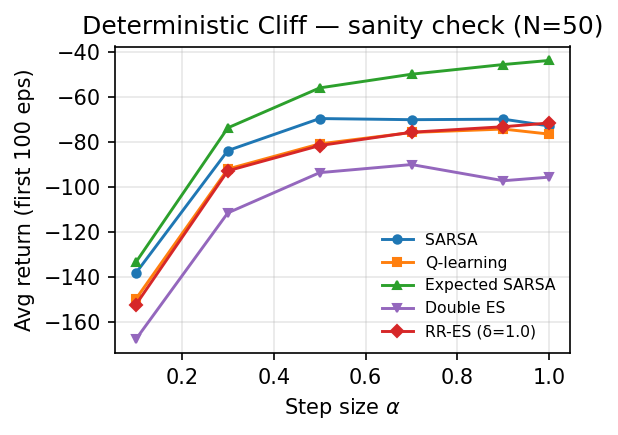

In [4]:
fig, ax = plt.subplots(figsize=(4, 3), dpi=150)
for name, vals in results.items():
    ax.plot(ALPHAS, vals, label=name, marker=METHOD_MARKERS[name],
            color=METHOD_COLORS[name], linewidth=1.4, markersize=4)
ax.set_xlabel(r'Step size $\alpha$')
ax.set_ylabel(f'Avg return (first {N_EPISODES} eps)')
ax.set_title(f'Deterministic Cliff — sanity check (N={N_RUNS})')
ax.legend(frameon=False, fontsize=7.5, loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../results/figures/01_sanity_all_methods.png', dpi=200, bbox_inches='tight')
plt.show()
